# Population summary: units in or near chosen 5-HT core meshes

Pick meshes (default B5 and B8 CS cores), a distance range from their surface, tagged and/or untagged units, a minimum spike count and QC; the first cells report how many units that selects, the later cells characterize them.

* **Tagged** = `basic_ephys_all_DRN` (as `unit_summary_DRN_population_options.py`); everything else is untagged.
* **Distance** = distance (um) from the unit's CCF location to the nearest chosen mesh's filled volume, 0 inside (10 um voxels).
* **Drift cuts**: `DRIFT_CUTS = 'none'` uses the whole recording. Once cuts exist, set `'existing'` (tagged `_opto_drift_tbl.csv`, then the hand-placed `_opto_drift_tbl_nontagged.csv`) or `'sheet'` (a cut sheet written by the *Drift candidates* section, filled in by hand) and re-run; PSTHs are recomputed only for units whose cut changed.

Helpers live in `cs_population_DRN.py`; caches in `/root/capsule/scratch/combined/cs_population_DRN/`. The first run builds per-session caches (~1-2 min for the unit cache, a few minutes for PSTHs, 8 parallel jobs).

In [20]:
import os
import sys
import warnings
# the helpers sit next to this notebook; the kernel may start elsewhere (e.g. /root/capsule)
CODE_DIR = '/root/capsule/code/beh_ephys_analysis'
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)
import numpy as np
import pandas as pd
%load_ext autoreload
%autoreload 2
import cs_population_DRN as cp  # autoreload: edits to the helper module apply without a kernel restart
%matplotlib inline
warnings.filterwarnings('ignore', category=RuntimeWarning)  # NaN means over empty bins / units without a condition
pd.set_option('display.width', 200)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Parameters

In [21]:
MESHES_OF_INTEREST = ['DR', 'wing']   # any of: 'B5', 'B8', 'DR', 'wing', 'B9', 'B3', 'B1', 'B1+B2'
DIST_UM = (0, 100)                  # [min, max] um from the nearest chosen mesh; 0 = inside. e.g. (50, 400)
DIST_BIN_EDGES_UM = [0, 50, 100]    # distance bins for the count table and GROUP_BY = 'distance'
GROUPS = ['tagged']               # 'tagged' and/or 'untagged'
MIN_SPIKES = 200                    # more than this many spikes in the session
REQUIRE_DEFAULT_QC = True           # default_qc and not decoder noise/artifact
MAX_ISI = 0.1                       # keep isi_violations_ratio < MAX_ISI; None = no limit
MIN_FIRING_RATE = None              # Hz
EXCLUDE_MESHES = []                 # e.g. ['DR', 'wing'] to drop units within EXCLUDE_WITHIN_UM of the DR core / wing
EXCLUDE_WITHIN_UM = 0
EXCLUDE_OPTO_RESPONSIVE = False     # drop untagged units that responded to light without passing the tagged filter
SESSIONS = None                     # list of sessions, or None for all

GROUP_BY = 'nearest_mesh'           # how plots split units: 'group' (tagged/untagged), 'nearest_mesh', 'distance'
NORMALIZE = 'delta'                 # PSTHs: 'delta' (rate - baseline, Hz) or 'zscore' (baseline trial SD)

DRIFT_CUTS = 'none'                 # 'none' | 'existing' | 'sheet'
CUT_SHEET = None                    # path of the filled-in sheet when DRIFT_CUTS == 'sheet'
MIN_SPIKES_AFTER_CUT = True         # with cuts, also require > MIN_SPIKES spikes inside the cut

SAVE_FIGS = False                   # write each figure as PDF to FIG_DIR
FIG_DIR = os.path.join(cp.CACHE_DIR, 'figures', '_'.join(MESHES_OF_INTEREST) + f'_{DIST_UM[0]}-{DIST_UM[1]}um_' + '_'.join(GROUPS))
N_JOBS = 8


def save(fig, name):
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, f'{name}.pdf'), bbox_inches='tight')

## Selection: how many units?

In [22]:
master = cp.master_units()
sel, funnel = cp.select_units(master, meshes=MESHES_OF_INTEREST, dist_um=DIST_UM, groups=GROUPS,
                              min_spikes=MIN_SPIKES, require_default_qc=REQUIRE_DEFAULT_QC, max_isi=MAX_ISI,
                              min_firing_rate=MIN_FIRING_RATE, exclude_meshes=EXCLUDE_MESHES,
                              exclude_within_um=EXCLUDE_WITHIN_UM, exclude_opto_responsive=EXCLUDE_OPTO_RESPONSIVE,
                              sessions=SESSIONS, n_jobs=N_JOBS)
sel['distance'] = cp.distance_bins(sel, DIST_BIN_EDGES_UM)
print(f"Selected: {(sel['group'] == 'tagged').sum()} tagged, {(sel['group'] == 'untagged').sum()} untagged units "
      f"in {sel['session'].nunique()} sessions / {sel['session'].str.split('_').str[1].nunique()} mice")
display(funnel)
display(cp.counts_table(sel, DIST_BIN_EDGES_UM))

Selected: 168 tagged, 0 untagged units in 37 sessions / 14 mice


,step,tagged,untagged
0,all units in master table,194,11069
1,CCF location,194,9460
2,0-100 um from DR / wing,168,3531
3,"default_qc, not noise/artifact",168,1772
4,ISI violations ratio < 0.1,168,1210
5,> 200 spikes in session,168,1076
6,groups: tagged,168,0


group                   tagged  sessions
nearest_mesh distance                   
DR           0-50 um        14        11
             50-100 um      14        10
             inside        129        27
wing         0-50 um         5         3
             50-100 um       2         1
             inside          4         3

In [23]:
# units per session (and mouse), largest first
per_session = (sel.groupby('session').agg(units=('unit_id', 'size'), tagged=('tagged', 'sum'),
                                          median_dist_um=('dist_um', 'median'),
                                          nearest=('nearest_mesh', lambda x: ', '.join(sorted(set(x)))))
               .sort_values('units', ascending=False))
per_session

,units,tagged,median_dist_um,nearest
session,,,,
behavior_844917_2026-06-04_12-30-01,27,27,0.000000,DR
behavior_841598_2026-05-01_14-15-09,17,17,0.000000,DR
behavior_838332_2026-03-11_13-01-00,12,12,0.000000,DR
behavior_838332_2026-03-13_12-29-22,9,9,0.000000,DR
behavior_848869_2026-05-12_08-51-54,9,9,0.000000,DR
behavior_826159_2026-01-26_15-15-12,8,8,0.000000,DR
behavior_843661_2026-04-28_09-49-53,8,8,0.000000,DR
behavior_838332_2026-03-12_13-31-08,6,6,0.000000,DR
behavior_826159_2026-01-23_13-34-11,6,6,11.180340,"DR, wing"


## Anatomy: units in three planes

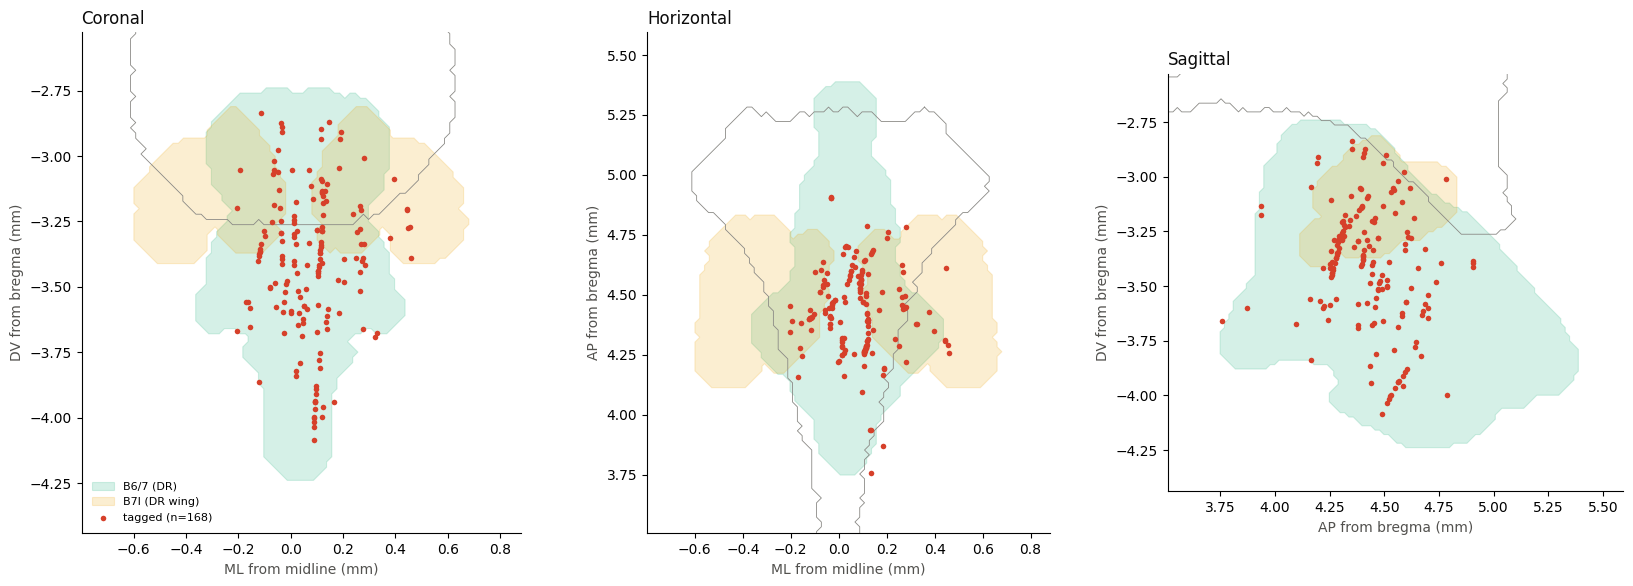

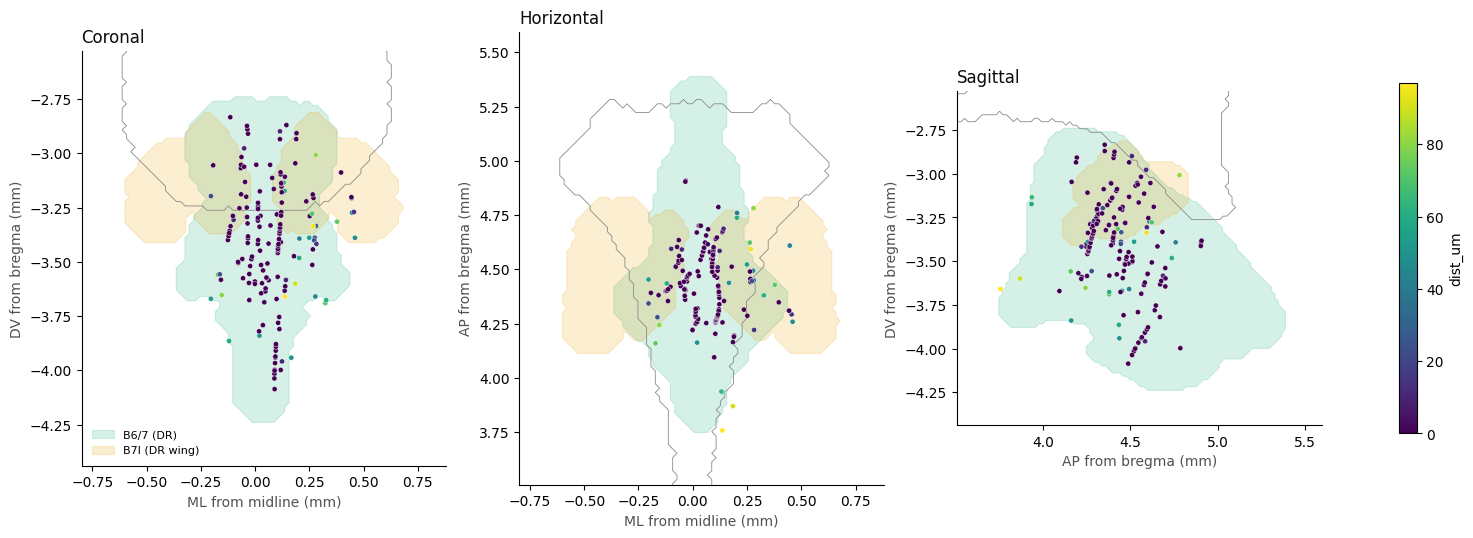

In [24]:
fig = cp.plane_maps(sel, MESHES_OF_INTEREST, color_by='group'); save(fig, 'planes_group')
fig = cp.plane_maps(sel, MESHES_OF_INTEREST, color_by='dist_um'); save(fig, 'planes_distance')

## Unit metrics (whole session, no drift cut)

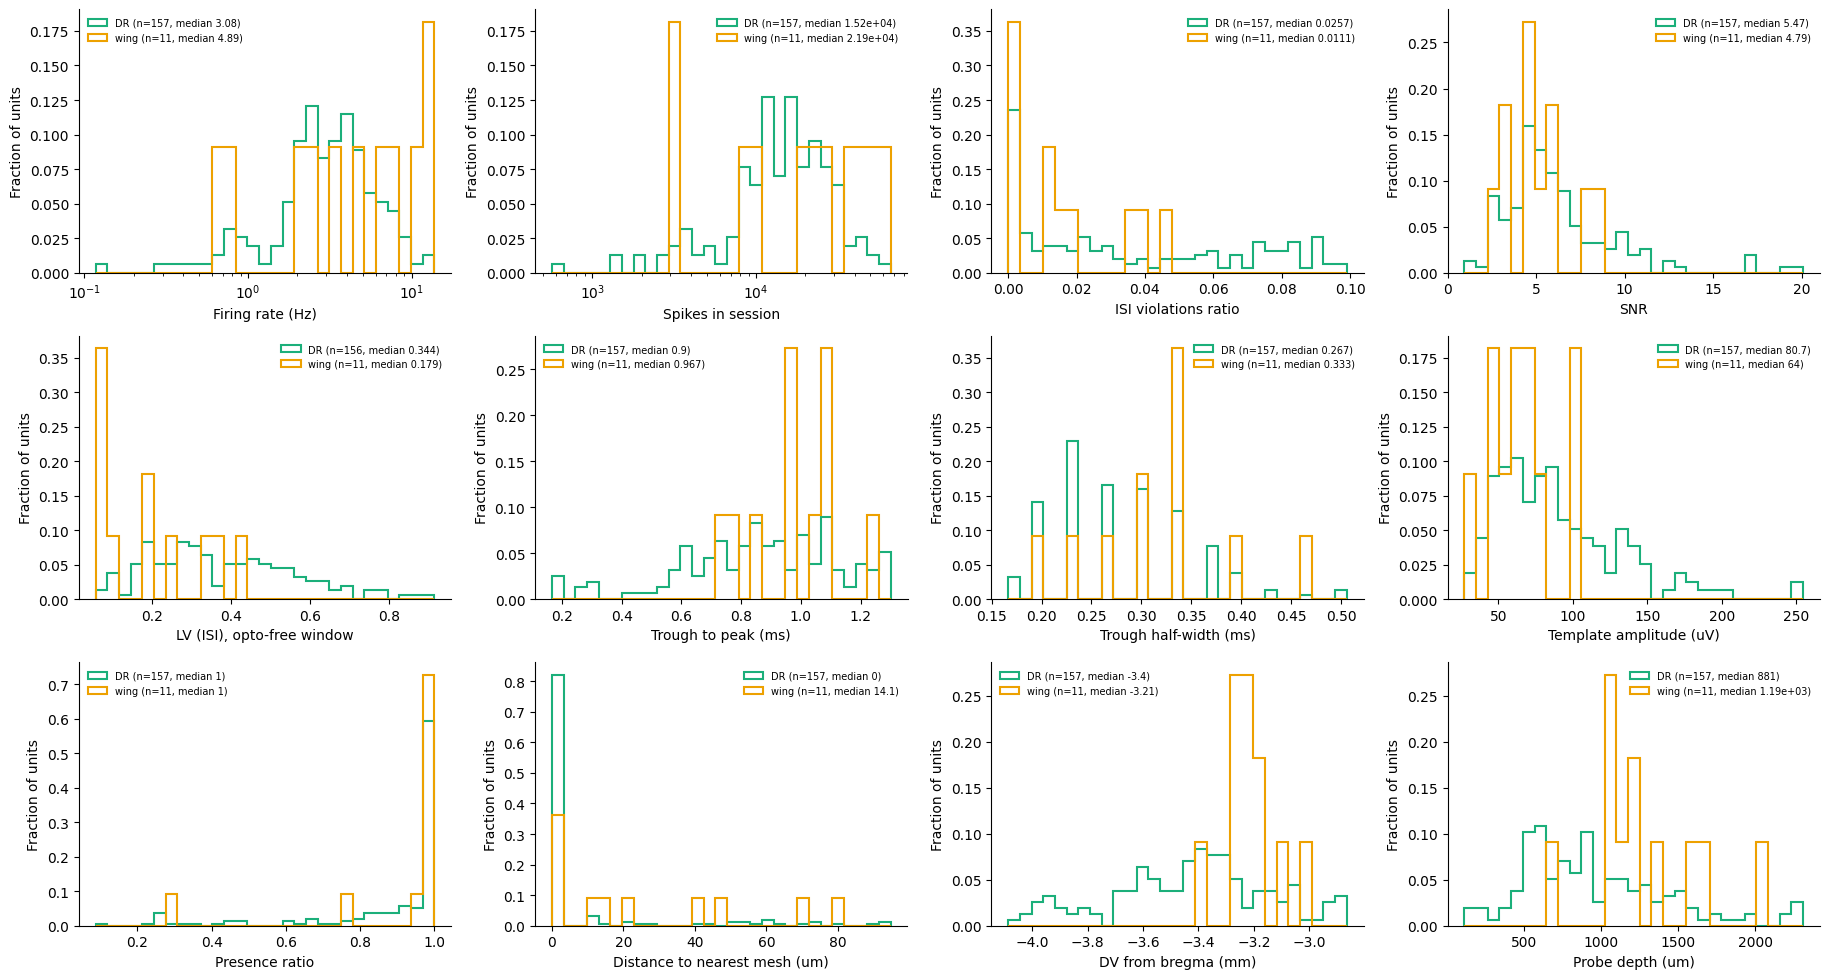

In [25]:
fig = cp.metric_hists(sel, groups_by=GROUP_BY); save(fig, 'metrics')

## Drift candidates (to decide on manual cuts)

Each unit's rate in 60 s bins as log2 of its own median (opto blocks included); `rate_stability` = log2(max / min) of the 5-min smoothed rate inside the opto-free window. Units on top change most. Existing cuts are drawn as black ticks once `DRIFT_CUTS` is set.

rate_stability > 2 (4-fold rate change): 86 of 168 units


,session,unit_id,group,nearest_mesh,dist_um,firing_rate,n_spikes,rate_stability
76,behavior_841861_2026-04-03_13-18-22,37,tagged,DR,0.000000,3.079149,14277,7.241586
64,behavior_838332_2026-03-13_12-29-22,120,tagged,DR,0.000000,1.967446,8704,6.902878
156,behavior_844917_2026-06-04_12-30-01,120,tagged,DR,0.000000,6.758959,32893,6.876517
25,behavior_826164_2026-01-29_11-09-03,180,tagged,DR,0.000000,1.901251,8623,6.765977
77,behavior_841861_2026-04-03_13-18-22,46,tagged,DR,0.000000,4.102512,19022,6.732304
113,behavior_841598_2026-05-01_14-15-09,114,tagged,DR,10.000000,1.761259,9925,6.676192
100,behavior_841598_2026-04-30_13-45-07,99,tagged,DR,41.231056,4.906148,23558,6.555100
42,behavior_838332_2026-03-10_13-23-52,122,tagged,DR,0.000000,2.509724,12734,6.550197
85,behavior_843661_2026-04-28_09-49-53,206,tagged,DR,0.000000,3.856916,19299,6.536053
115,behavior_841598_2026-05-01_14-15-09,194,tagged,DR,0.000000,4.174138,23522,6.273796


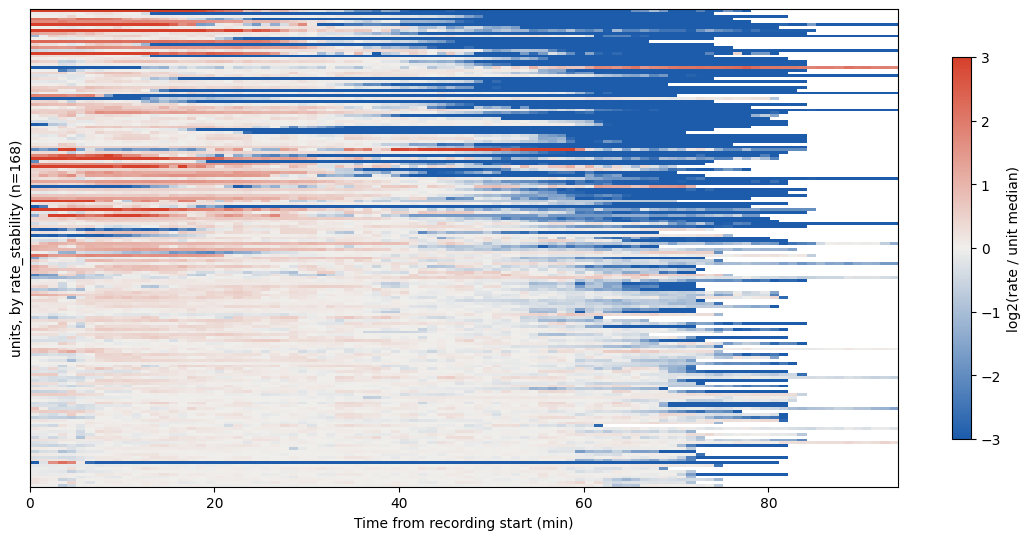

In [26]:
sel = cp.stability_index(sel)
fig = cp.stability_heatmap(cp.drift_cuts(sel, 'existing') if DRIFT_CUTS != 'none' else sel); save(fig, 'stability')
print(f"rate_stability > 2 (4-fold rate change): {(sel['rate_stability'] > 2).sum()} of {len(sel)} units")
sel.sort_values('rate_stability', ascending=False)[['session', 'unit_id', 'group', 'nearest_mesh', 'dist_um', 'firing_rate',
                                                     'n_spikes', 'rate_stability']].head(20)

In [27]:
# Write a cut sheet for this selection (unit_summary_DRN_drift_cut_sheet.py columns, pre-filled with
# any existing cuts). Fill ephys_cut_start / ephys_cut_end (s) or exclude, then set DRIFT_CUTS = 'sheet'
# and CUT_SHEET to the file. Never overwrites a sheet.
WRITE_SHEET = False
if WRITE_SHEET:
    stamp = pd.Timestamp.now().strftime('%Y%m%d_%H%M')
    print(cp.write_cut_sheet(sel.sort_values(['session', 'unit_id']),
                             os.path.join(cp.CACHE_DIR, 'cut_sheets', f'cut_sheet_{"_".join(MESHES_OF_INTEREST)}_{stamp}.csv')))

# Optional: per-unit drift PDFs (same figure as the tagged units' drift review) into a review folder;
# does not touch any drift table.
MAKE_DRIFT_PDFS = False
if MAKE_DRIFT_PDFS:
    from drift_analysis import plot_session_opto_drift
    for s, rows in sel.groupby('session'):
        plot_session_opto_drift(s, 'raw', plot=True, update_csv=False, update_cut=False,
                                unit_ids=rows['unit_id'].tolist(),
                                out_dir=os.path.join(cp.CACHE_DIR, 'drift_review', s))

## Apply drift cuts and compute PSTHs

In [28]:
selc = cp.drift_cuts(sel, DRIFT_CUTS, CUT_SHEET)
print('cut source:', selc['cut_source'].value_counts().to_dict())
psths = cp.population_psths(selc, n_jobs=N_JOBS)
selc = cp.add_cut_stats(selc, psths)
if DRIFT_CUTS != 'none' and MIN_SPIKES_AFTER_CUT:
    n0 = len(selc)
    selc = selc[selc['n_spikes_cut'] > MIN_SPIKES].reset_index(drop=True)
    print(f'{n0 - len(selc)} units dropped with <= {MIN_SPIKES} spikes inside their cut')
print(f"{len(selc)} units; {int((selc['n_trials'] > 0).sum())} with behavior trials "
      f"(median {selc.loc[selc['n_trials'] > 0, 'n_trials'].median():.0f} trials)")
groups = cp.make_groups(selc, GROUP_BY)
list(groups)

cut source: {'none': 168}
computing PSTHs for 163 units in 37 sessions...


/opt/conda/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/conda/lib/python3.12/site-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/opt/conda/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/conda/lib/python3.12/site-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/opt/conda/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/conda/lib/python3.12/site-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/opt/conda/lib/python3

168 units; 168 with behavior trials (median 404 trials)


['DR (n=157)', 'wing (n=11)']

## Population PSTHs (mean +/- SEM across units)

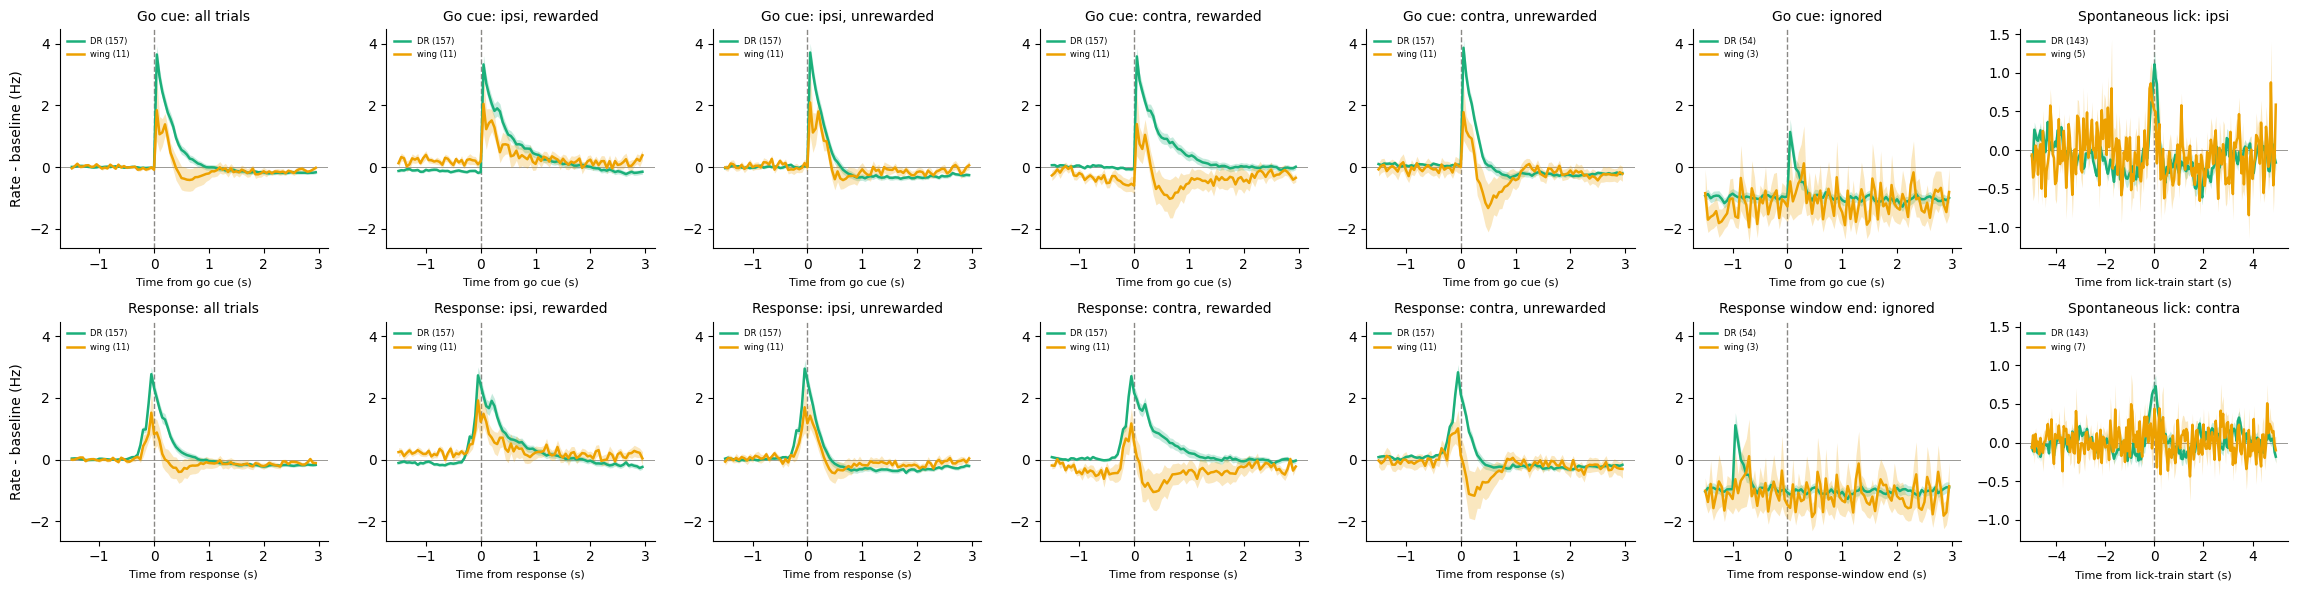

In [29]:
fig = cp.psth_grid(psths, groups, normalize=NORMALIZE); save(fig, 'psth_grid')

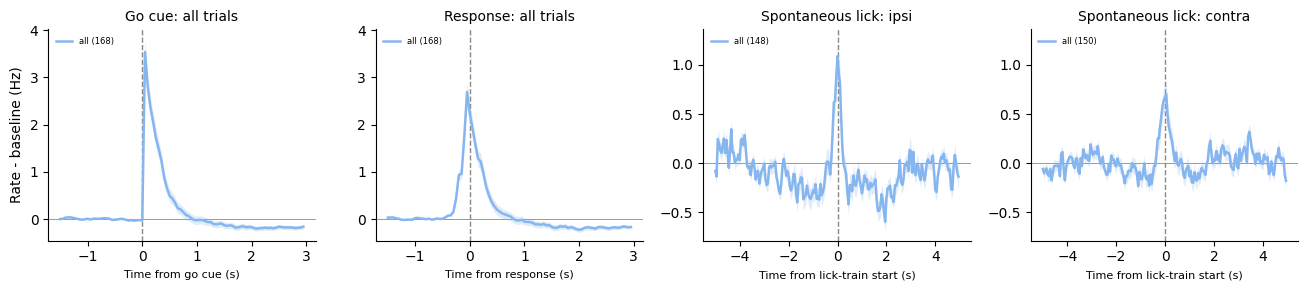

In [30]:
# all units pooled, for reference against the split above
fig = cp.psth_grid(psths, cp.make_groups(selc.assign(all='all'), 'all'), normalize=NORMALIZE,
                   rows=[[('go_cue_all', 'Go cue: all trials'), ('response_all', 'Response: all trials'),
                          ('spont_ipsi', 'Spontaneous lick: ipsi'), ('spont_contra', 'Spontaneous lick: contra')]])
save(fig, 'psth_pooled')

## Colormap rasters: one row per unit (normalized mean rate), sorted by 0-0.5 s go-cue response

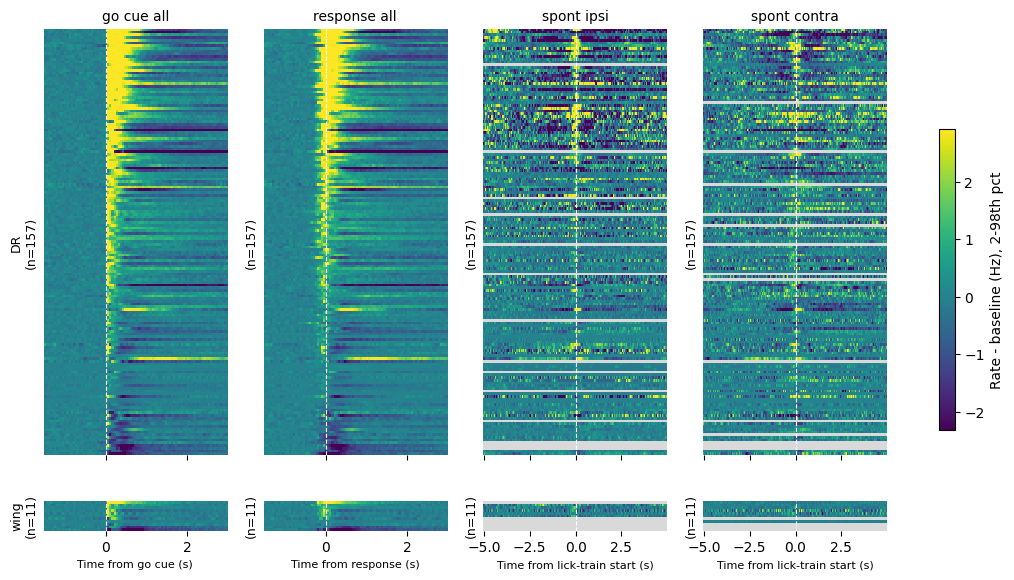

In [31]:
fig = cp.population_heatmaps(psths, groups, normalize=NORMALIZE); save(fig, 'heatmaps')

## Response profiles (`unit_response_profiles_DRN` classes: early 0-0.5 s / late 0.5-2.5 s vs pre-go-cue baseline)

profile_go_cue,sustained excitation,transient excitation,inhibited,non-responsive
nearest_mesh,,,,
DR,0.08,0.48,0.09,0.35
wing,0.00,0.45,0.09,0.45


profile_go_cue,sustained excitation,transient excitation,inhibited,non-responsive
distance,,,,
0-50 um,0.05,0.42,0.11,0.42
50-100 um,0.06,0.50,0.00,0.44
inside,0.08,0.49,0.10,0.34


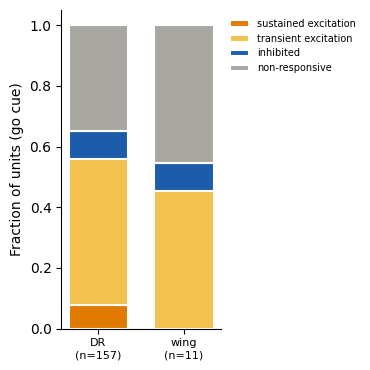

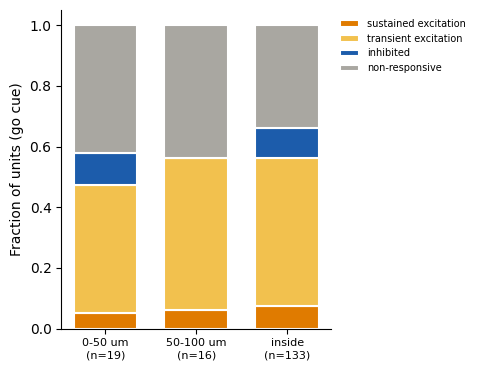

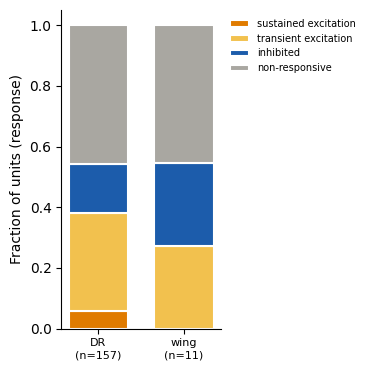

In [32]:
selr = cp.response_profiles(selc, psths)
fig, t = cp.profile_counts(selr, GROUP_BY, 'go_cue'); save(fig, 'profiles_go_cue'); display(t.round(2))
fig, t = cp.profile_counts(selr, 'distance', 'go_cue'); save(fig, 'profiles_by_distance'); display(t.round(2))
fig, t = cp.profile_counts(selr, GROUP_BY, 'response'); save(fig, 'profiles_response')

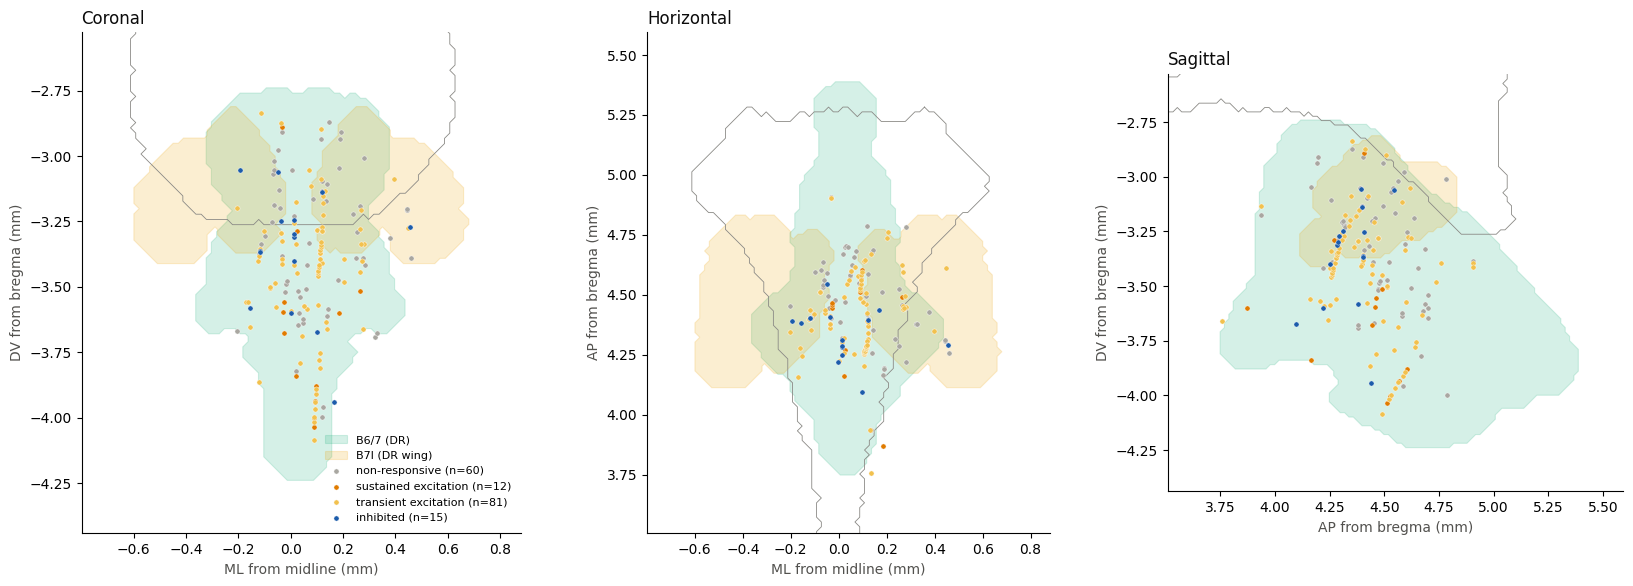

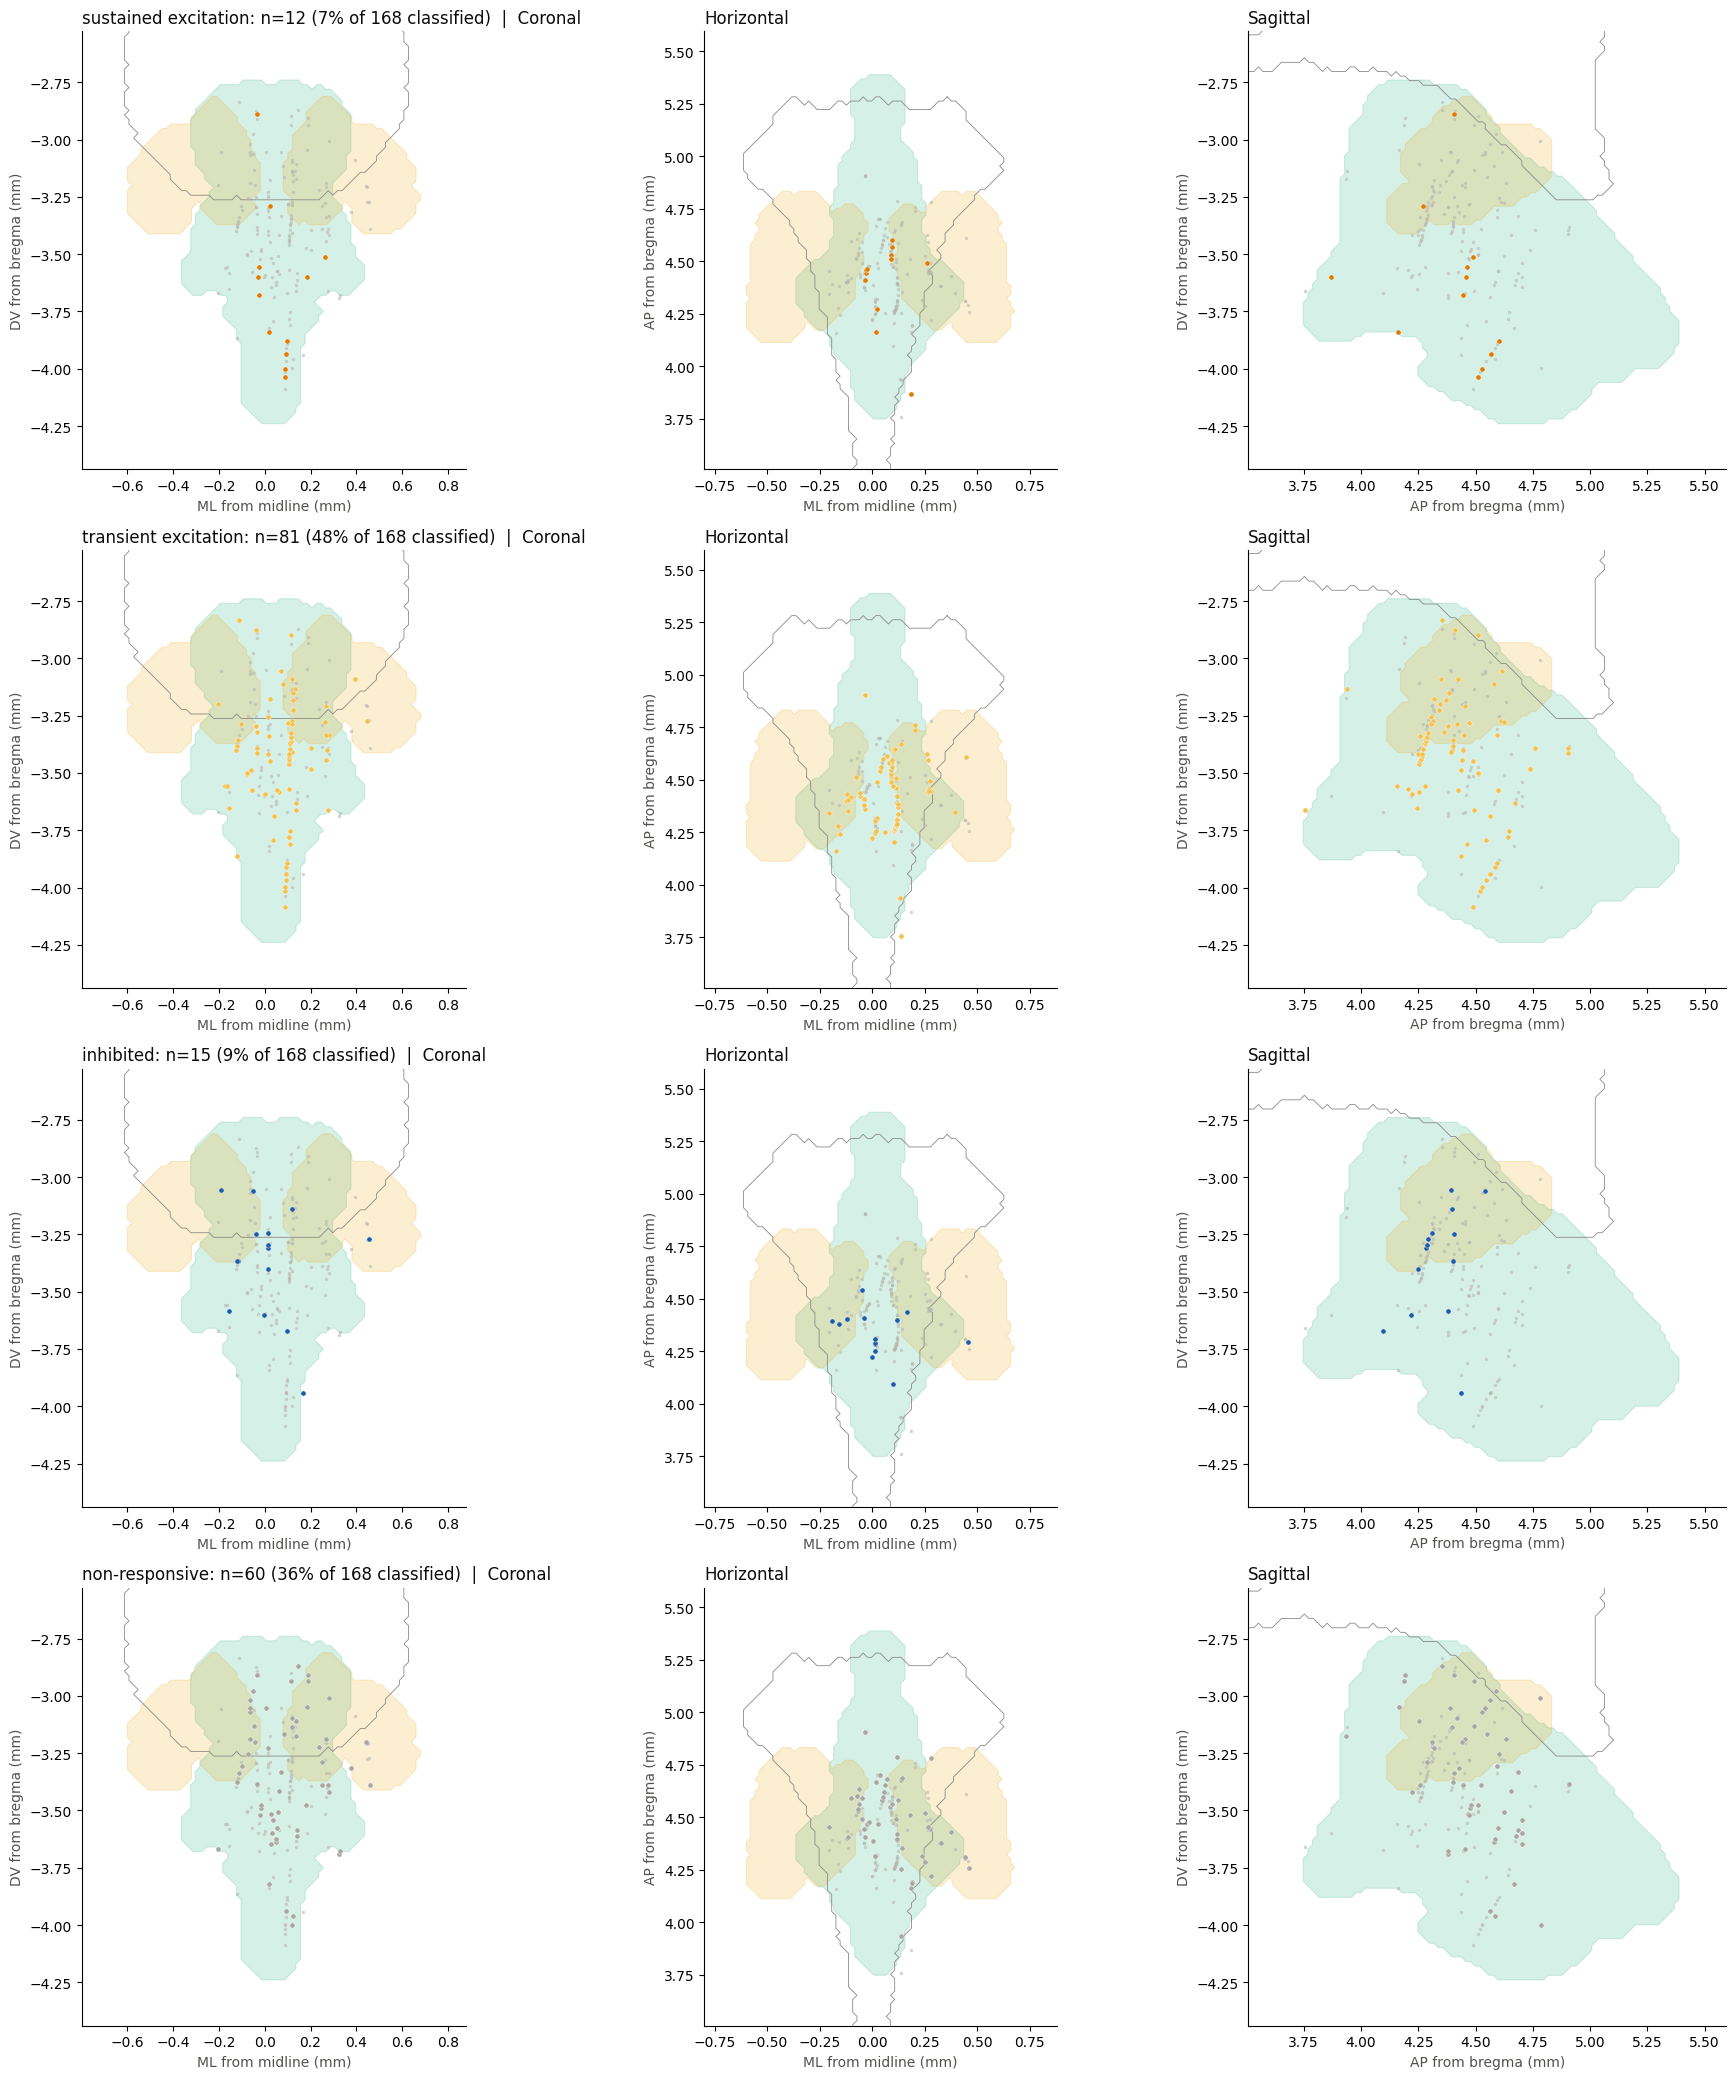

In [33]:
# where each response type sits: all classes together (non-responsive at the back), then one row per class
# over the other units in gray. PROFILE_ALIGN: 'go_cue' or 'response'
PROFILE_ALIGN = 'go_cue'
fig = cp.plane_maps(selr, MESHES_OF_INTEREST, color_by=f'profile_{PROFILE_ALIGN}'); save(fig, f'planes_profile_{PROFILE_ALIGN}')
fig = cp.plane_maps_by_category(selr, MESHES_OF_INTEREST, f'profile_{PROFILE_ALIGN}'); save(fig, f'planes_profile_{PROFILE_ALIGN}_split')

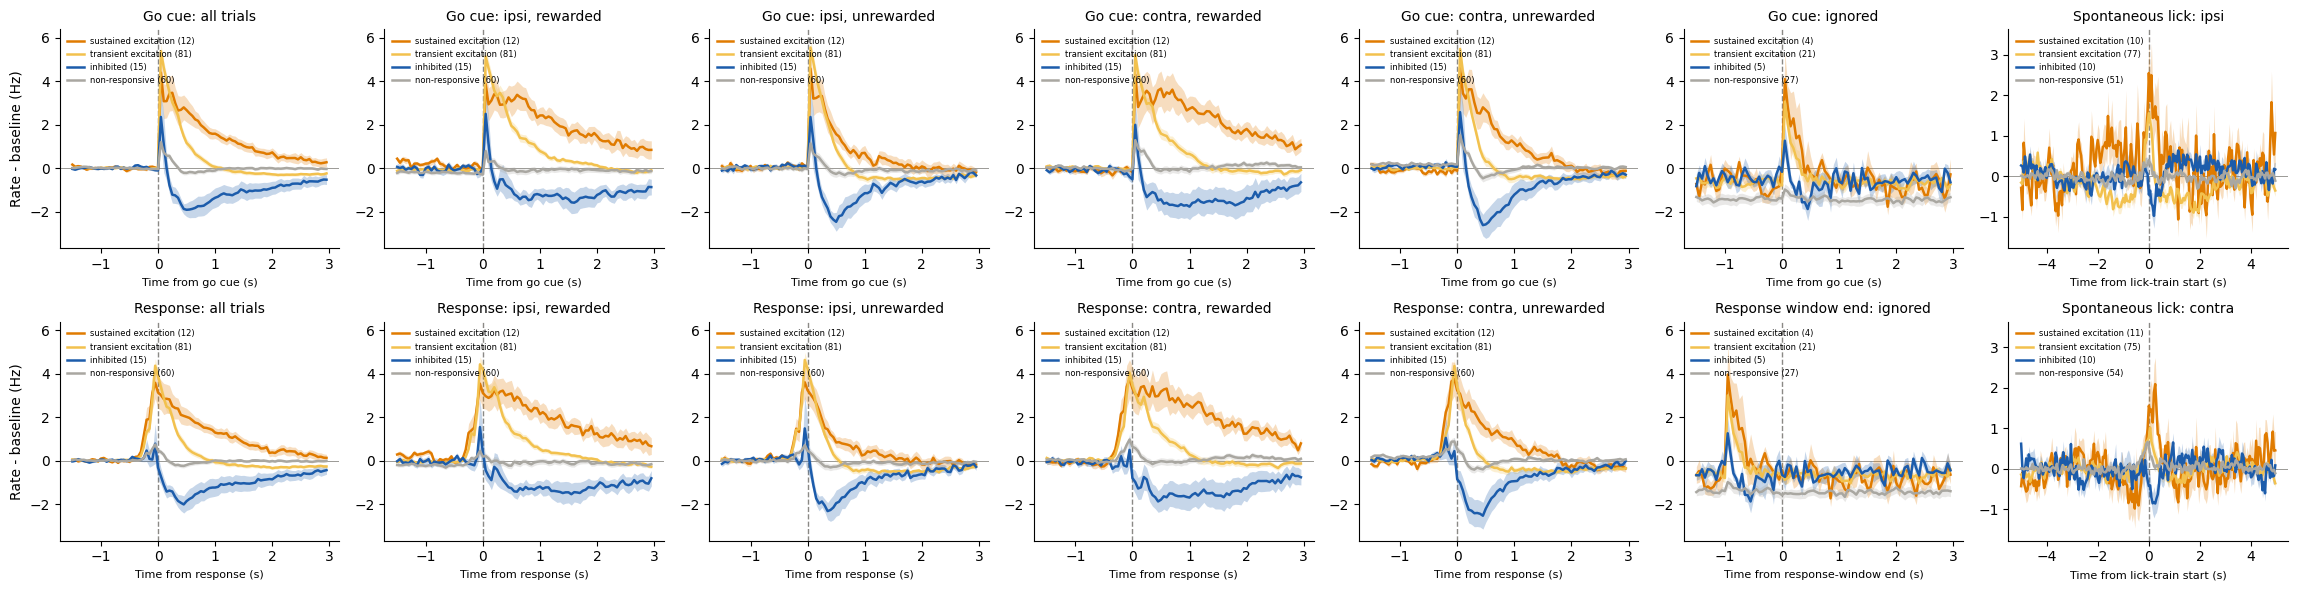

In [34]:
# profile groups as PSTHs
pgroups = {f'{p} (n={(selr["profile_go_cue"] == p).sum()})':
           (list(zip(selr.loc[selr['profile_go_cue'] == p, 'session'], selr.loc[selr['profile_go_cue'] == p, 'unit_id'])),
            cp.PROFILE_COLORS[p]) for p in cp.PROFILES if (selr['profile_go_cue'] == p).any()}
fig = cp.psth_grid(psths, pgroups, normalize=NORMALIZE); save(fig, 'psth_by_profile')

## Example units: trial x time colormap rasters (go cue, all trials)

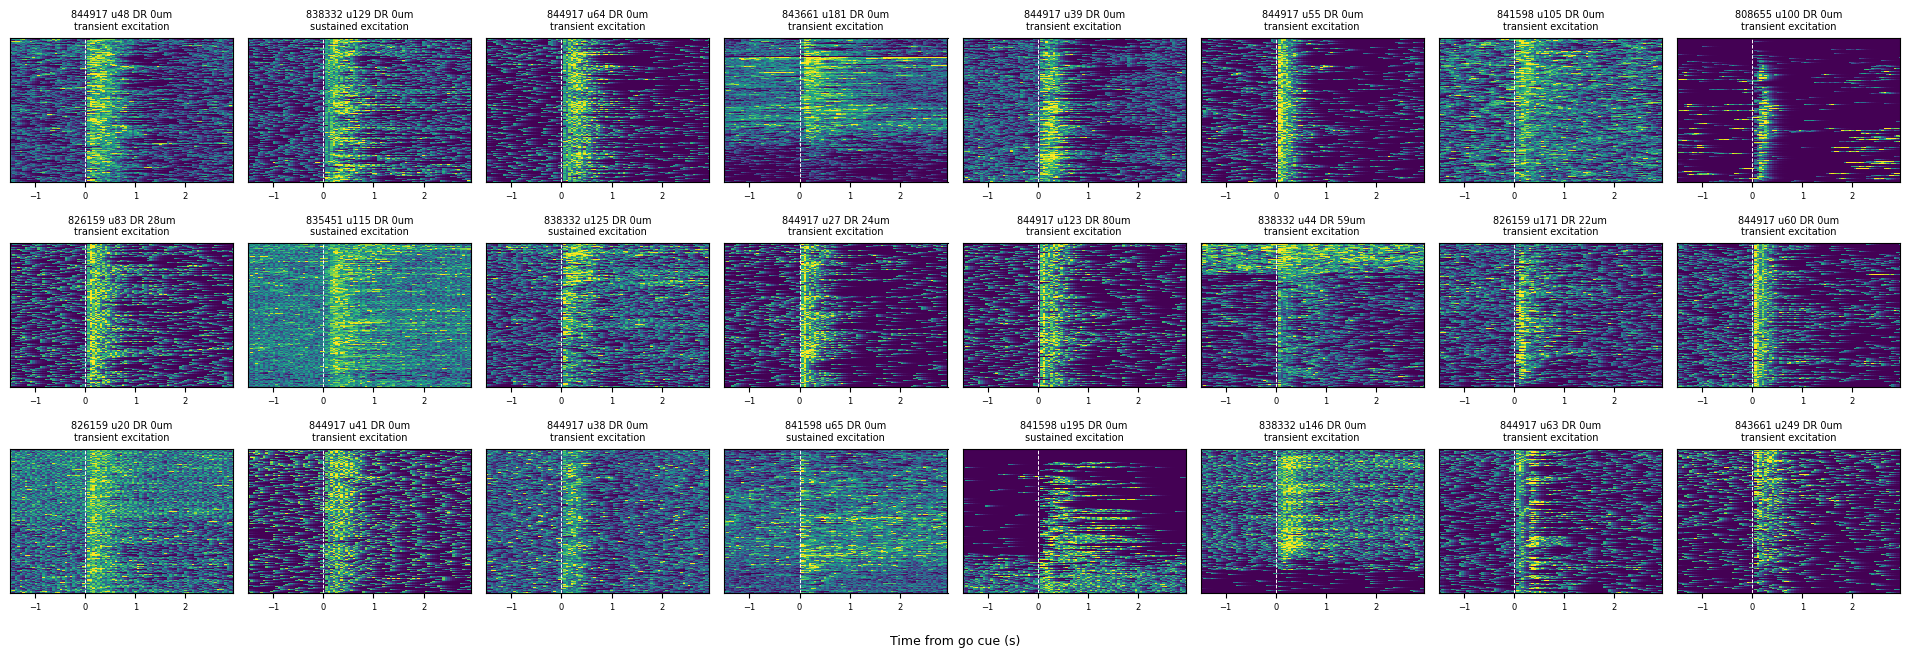

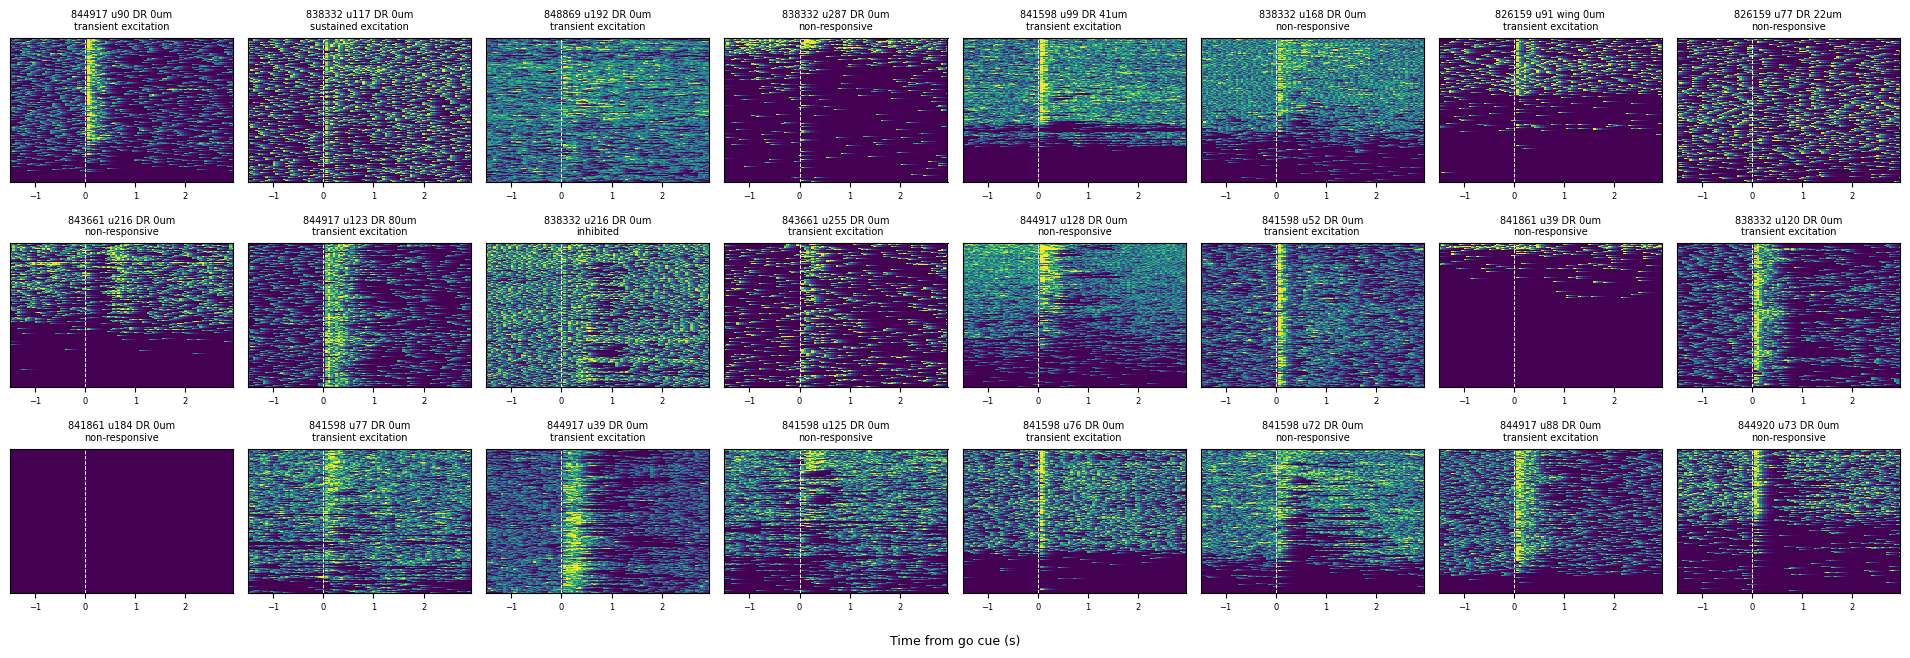

In [35]:
N_EXAMPLES = 24
d = selr.dropna(subset=['delta_early_go_cue'])
top = d.reindex(d['delta_early_go_cue'].abs().sort_values(ascending=False).index).head(N_EXAMPLES)
titles = {(r.session, r.unit_id): f"{r.session.split('_')[1]} u{r.unit_id} {r.nearest_mesh} {r.dist_um:.0f}um\n"
          f"{r.profile_go_cue}" for r in selr.itertuples()}
fig = cp.unit_rasters(psths, list(zip(top['session'], top['unit_id'])), 'go_cue_all', titles=titles); save(fig, 'examples_top')
rnd = d.sample(min(N_EXAMPLES, len(d)), random_state=0)
fig = cp.unit_rasters(psths, list(zip(rnd['session'], rnd['unit_id'])), 'go_cue_all', titles=titles); save(fig, 'examples_random')

## Average waveforms (peak-channel template, baseline-subtracted, trough = -1)

3 of 168 templates left out as outliers (> 6 robust SD)


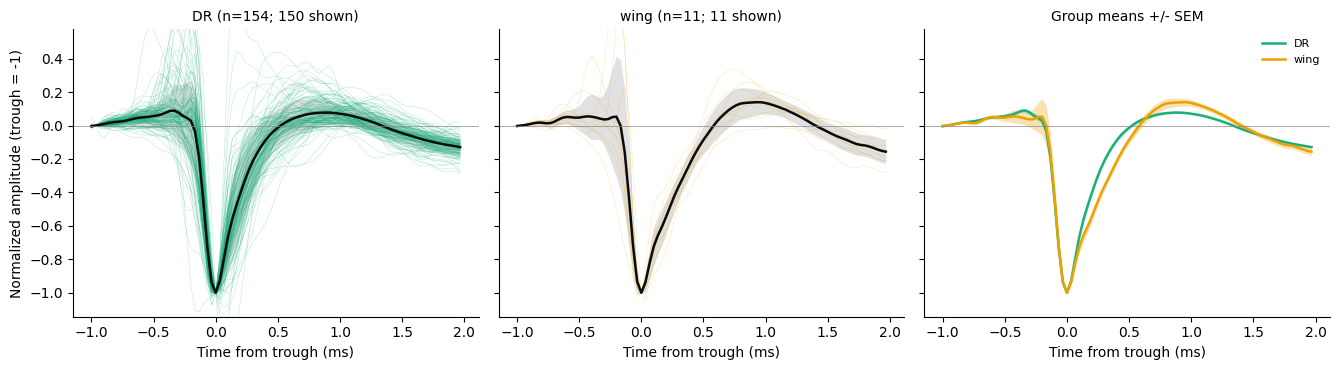

In [36]:
WF_YLIM = 'auto'      # (lo, hi), 'auto' (0.5-99.5th percentile of all template samples, padded) or None
WF_DROP_OUTLIERS = 6  # leave out templates > this many robust SD from the median on PC1/PC2 (as the PCA); None keeps all
fig = cp.waveform_panels(selc, groups, ylim=WF_YLIM, outlier_sd=WF_DROP_OUTLIERS); save(fig, 'waveforms')

## Waveform PCA quartiles (one PCA over the selection)

3 of 168 templates left out of the PCA as outliers (> 6 robust SD)


profile_go_cue,inhibited,non-responsive,sustained excitation,transient excitation
wf_pc1_quartile,,,,
Q1,0.10,0.31,0.10,0.50
Q2,0.12,0.24,0.07,0.56
Q3,0.02,0.49,0.07,0.41
Q4,0.12,0.34,0.05,0.49


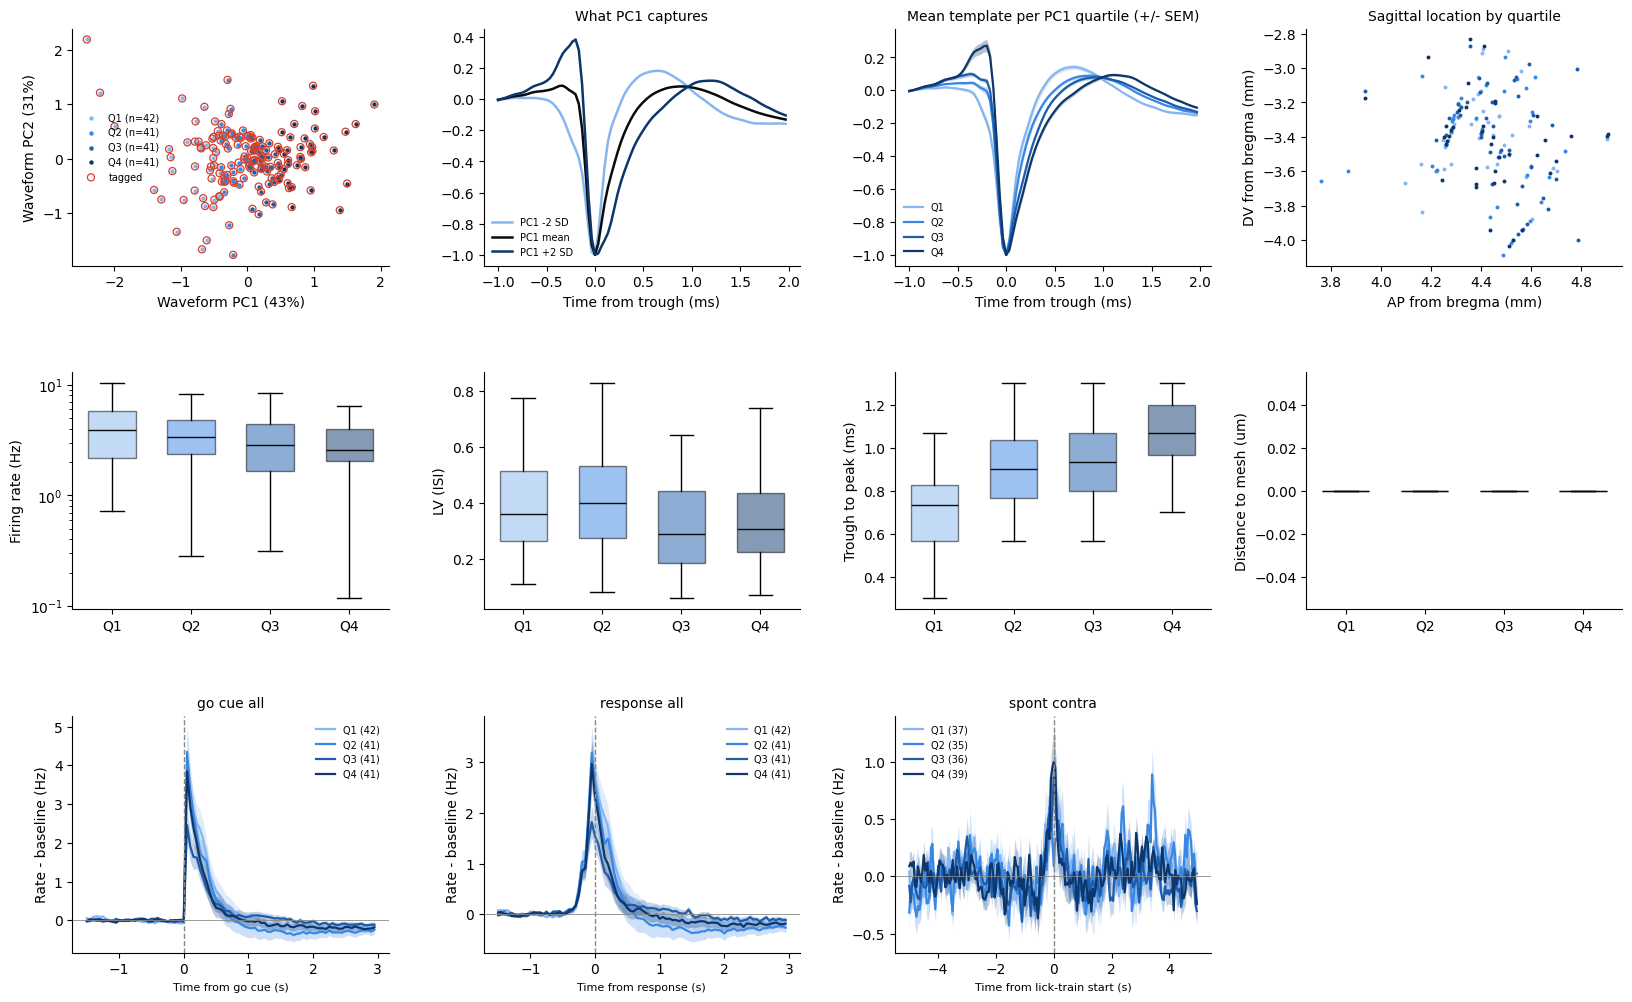

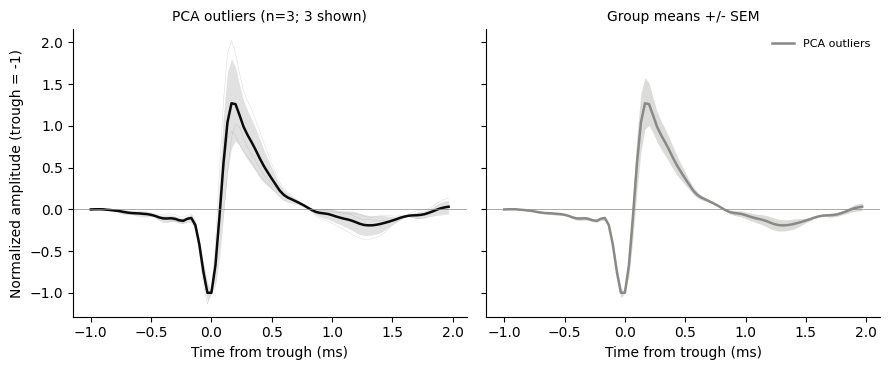

In [37]:
WF_OUTLIER_SD = 6  # templates this far (robust SD) from the median on PC1/PC2 are left out of the PCA; None keeps all
selp, pca = cp.waveform_pca(selr, outlier_sd=WF_OUTLIER_SD)
fig = cp.pca_quartile_panels(selp, pca, psths, normalize=NORMALIZE); save(fig, 'waveform_pca_quartiles')
# the outlier templates, for a look
out_keys = list(zip(selp.loc[selp['wf_outlier'], 'session'], selp.loc[selp['wf_outlier'], 'unit_id']))
if out_keys:
    fig = cp.waveform_panels(selp[selp['wf_outlier']], {f'PCA outliers (n={len(out_keys)})': (out_keys, cp.MUTED)})
pd.crosstab(selp['wf_pc1_quartile'], selp['profile_go_cue'], normalize='index').round(2)

## Save the selection

In [38]:
out = os.path.join(cp.CACHE_DIR, 'selections', os.path.basename(FIG_DIR) + f'_cuts-{DRIFT_CUTS}.csv')
os.makedirs(os.path.dirname(out), exist_ok=True)
selp.drop(columns=['wf', 'rate_course', 'spont_window']).to_csv(out, index=False)
print(out)

/root/capsule/scratch/combined/cs_population_DRN/selections/DR_wing_0-100um_tagged_cuts-none.csv
